# Importacion

In [2]:
import pandas as pd

pd.set_option('display.max_colwidth', None)

Cargamos el dataset

In [3]:
df = pd.read_csv('csv/dataset_final.csv')

# Columnas

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 59 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   img_original             29999 non-null  object 
 1   img_recodificada         29999 non-null  object 
 2   metodo                   29999 non-null  object 
 3   formato_salida           29999 non-null  object 
 4   calidad                  29999 non-null  int64  
 5   orig_media_lum           29999 non-null  float64
 6   orig_var_lum             29999 non-null  float64
 7   orig_rango               29999 non-null  float64
 8   orig_std                 29999 non-null  float64
 9   orig_michelson           29999 non-null  float64
 10  orig_hf                  29999 non-null  float64
 11  orig_lf                  29999 non-null  float64
 12  orig_hlfr                29999 non-null  float64
 13  orig_edges_s1            29999 non-null  float64
 14  orig_edges_s2         

In [5]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
 
# ------------------------------------------------------------------
# 0. CARGA DE DATOS
# ------------------------------------------------------------------
df = pd.read_csv("csv/dataset_completo.csv")
 
FEATURES = [
    "media_lum", "var_lum", "rango", "std", "michelson",
    "hf", "lf", "hlfr",
    "edges_s1", "edges_s2", "edges_s3",
    "grad_mean", "grad_std",
    "glcm_contrast", "glcm_hom", "glcm_energy", "glcm_corr",
    "entropia_shannon", "entropia_espectral", "entropia_gradiente", "entropia_glcm",
    "sat_mean", "sat_var", "hue_var",
    "megapixeles", "aspect_ratio",
]
 
ORIG_COLS = [f"orig_{f}" for f in FEATURES]
COMP_COLS = [f"comp_{f}" for f in FEATURES]

# 1. Reporte de valores faltantes

In [6]:
# ------------------------------------------------------------------
# 1. REPORTE DE VALORES FALTANTES
# ------------------------------------------------------------------
print("=" * 70)
print("1. VALORES FALTANTES POR COLUMNA")
print("=" * 70)
nulos = df[ORIG_COLS + COMP_COLS + ["lpips"]].isna().sum()
nulos = nulos[nulos > 0]
print(nulos.to_string() if len(nulos) else "Sin valores faltantes relevantes.")
print()

1. VALORES FALTANTES POR COLUMNA
orig_entropia_espectral      4
orig_hue_var               404
comp_entropia_espectral      4
comp_hue_var               446
lpips                       10



# 2. LPIPS: CRITERIO PRINCIPAL DE "MISMA IMAGEN"

In [7]:
print("=" * 70)
print("2. DISTRIBUCION DE LPIPS (similitud perceptual)")
print("=" * 70)
lpips_valid = df["lpips"].dropna()
print(lpips_valid.describe(percentiles=[.5, .9, .95, .99]).to_string())
 
UMBRAL_LPIPS = 0.10  # ajustar segun literatura/criterio del proyecto
tasa_validado = (lpips_valid < UMBRAL_LPIPS).mean() * 100
print(f"\n% de pares con LPIPS < {UMBRAL_LPIPS} (misma imagen, alta confianza): "
      f"{tasa_validado:.2f}%")
 
# LPIPS por calidad: debe bajar (mas similar) al subir la calidad
print("\nLPIPS promedio por nivel de calidad:")
print(df.groupby("calidad")["lpips"].mean().to_string())

2. DISTRIBUCION DE LPIPS (similitud perceptual)
count    29989.000000
mean         0.061067
std          0.089035
min          0.000000
50%          0.021126
90%          0.182943
95%          0.258648
99%          0.394983
max          0.645018

% de pares con LPIPS < 0.1 (misma imagen, alta confianza): 78.41%

LPIPS promedio por nivel de calidad:
calidad
10    0.145405
30    0.074571
50    0.048594
70    0.029765
90    0.008998


# 3. CORRELACION Y CONCORDANCIA POR FEATURE (orig vs comp)

In [8]:
def concordancia_lin(x, y):
    """Coeficiente de concordancia de Lin (CCC): mide acuerdo, no solo correlacion lineal."""
    x, y = np.asarray(x), np.asarray(y)
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(), y.var()
    sxy = np.mean((x - mx) * (y - my))
    return (2 * sxy) / (vx + vy + (mx - my) ** 2)
 
print("\n" + "=" * 70)
print("3. CORRELACION (Pearson r) Y CONCORDANCIA (CCC) POR FEATURE")
print("=" * 70)
resultados = []
for f in FEATURES:
    o, c = f"orig_{f}", f"comp_{f}"
    sub = df[[o, c]].dropna()
    if len(sub) < 10:
        continue
    r, p = stats.pearsonr(sub[o], sub[c])
    ccc = concordancia_lin(sub[o], sub[c])
    delta_rel = ((sub[c] - sub[o]) / (sub[o].replace(0, np.nan).abs())).median()
    resultados.append({
        "feature": f, "n": len(sub), "pearson_r": r,
        "ccc": ccc, "delta_rel_mediana_%": delta_rel * 100 if pd.notna(delta_rel) else np.nan
    })
 
tabla = pd.DataFrame(resultados).sort_values("pearson_r")
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
print(tabla.to_string(index=False))


3. CORRELACION (Pearson r) Y CONCORDANCIA (CCC) POR FEATURE
           feature     n  pearson_r    ccc  delta_rel_mediana_%
           var_lum 29999     0.0033 0.0000              -0.1322
               std 29999     0.0696 0.0093              -0.0661
         media_lum 29999     0.0809 0.0113               0.0000
              hlfr 29999     0.6813 0.6244              -1.6625
             rango 29999     0.7523 0.7513               0.0000
          glcm_hom 29999     0.8917 0.8558               2.1138
                hf 29999     0.9157 0.9071              -1.6494
entropia_gradiente 29999     0.9516 0.9422               0.0000
     entropia_glcm 29999     0.9525 0.9419              -0.2745
       glcm_energy 29999     0.9537 0.9504               0.6408
                lf 29999     0.9623 0.9603               0.0033
  entropia_shannon 29999     0.9673 0.9668              -0.0010
           sat_var 29999     0.9738 0.9737               0.0000
         glcm_corr 29999     0.9769 0.9738 

# 4. PRUEBA ESTADISTICA PAREADA (Wilcoxon) POR FEATURE

In [9]:
print("\n" + "=" * 70)
print("4. WILCOXON PAREADO (orig vs comp) + TAMANO DE EFECTO")
print("=" * 70)
wilcoxon_res = []
for f in FEATURES:
    o, c = f"orig_{f}", f"comp_{f}"
    sub = df[[o, c]].dropna()
    if len(sub) < 10:
        continue
    try:
        stat, p = stats.wilcoxon(sub[o], sub[c])
    except ValueError:
        continue
    diff = sub[c] - sub[o]
    cohen_d = diff.mean() / diff.std() if diff.std() > 0 else np.nan
    wilcoxon_res.append({"feature": f, "p_value": p, "cohen_d": cohen_d})
 
wtab = pd.DataFrame(wilcoxon_res)
print(wtab.to_string(index=False))
print("\nNota: con n≈30,000 casi todo sale 'significativo' (p<0.05); lo relevante "
      "es el tamano de efecto (Cohen's d). |d| < 0.2 => diferencia trivial, "
      "consistente con 'misma imagen, distinta codificacion'.")


4. WILCOXON PAREADO (orig vs comp) + TAMANO DE EFECTO
           feature  p_value  cohen_d
         media_lum   0.0000   0.0152
           var_lum   0.0000   0.0154
             rango   0.0000   0.0699
               std   0.0000   0.0154
         michelson   0.0000  -0.2694
                hf   0.0000  -0.1348
                lf   0.0000   0.1348
              hlfr   0.0000  -0.0578
          edges_s1   0.0000  -0.3495
          edges_s2   0.0000  -0.3737
          edges_s3   0.0000  -0.2986
         grad_mean   0.0000  -0.5197
          grad_std   0.0000  -0.5453
     glcm_contrast   0.0000  -0.3793
          glcm_hom   0.0000   0.6174
       glcm_energy   0.0000   0.1681
         glcm_corr   0.0000   0.2619
  entropia_shannon   0.0000  -0.1166
entropia_espectral   0.0000  -0.0952
entropia_gradiente   0.0000  -0.3854
     entropia_glcm   0.0000  -0.4739
          sat_mean   0.0000  -0.0934
           sat_var   0.0000   0.0724
           hue_var   0.0000  -0.2410
       megapixeles  

d:\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\scipy\stats\_wilcoxon.py:172: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
d:\TrabajoGrado\Codigos\Funciones_Matematicas\Generar_Dataset\lib\site-packages\scipy\stats\_wilcoxon.py:172: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


# 5. VISUALIZACION: dispersion orig vs comp + histograma LPIPS


Grafico guardado: validacion_scatter_features.png
Grafico guardado: validacion_lpips_hist.png


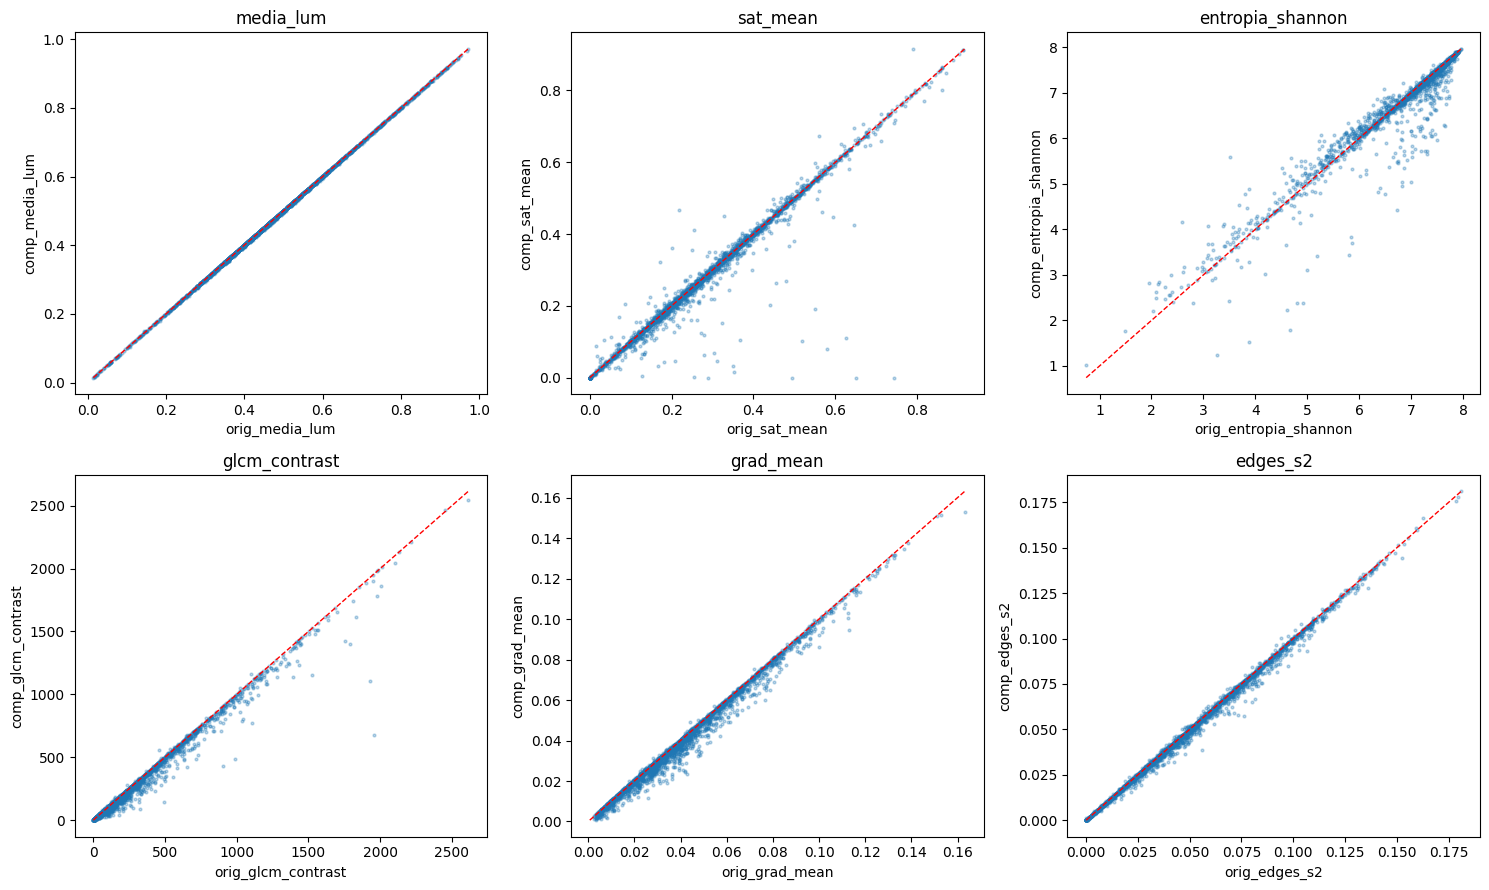

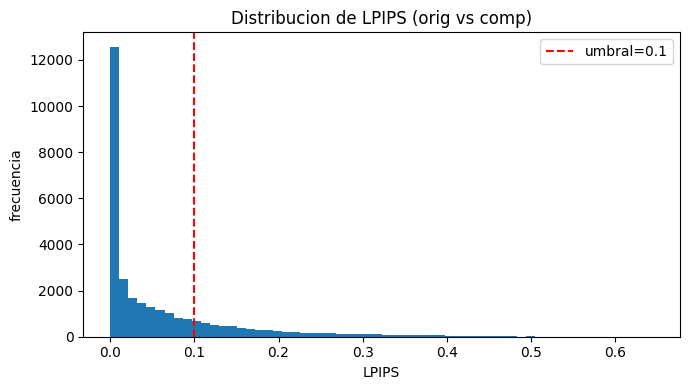

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
claves_clave = ["media_lum", "sat_mean", "entropia_shannon",
                 "glcm_contrast", "grad_mean", "edges_s2"]
 
for ax, f in zip(axes.ravel(), claves_clave):
    o, c = f"orig_{f}", f"comp_{f}"
    sub = df[[o, c]].dropna().sample(min(3000, len(df)), random_state=42)
    ax.scatter(sub[o], sub[c], s=4, alpha=0.3)
    lims = [sub[[o, c]].min().min(), sub[[o, c]].max().max()]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel(o)
    ax.set_ylabel(c)
    ax.set_title(f)
 
plt.tight_layout()
plt.savefig("validacion_scatter_features.png", dpi=150)
print("\nGrafico guardado: validacion_scatter_features.png")
 
plt.figure(figsize=(7, 4))
plt.hist(lpips_valid, bins=60)
plt.axvline(UMBRAL_LPIPS, color="r", linestyle="--", label=f"umbral={UMBRAL_LPIPS}")
plt.xlabel("LPIPS")
plt.ylabel("frecuencia")
plt.title("Distribucion de LPIPS (orig vs comp)")
plt.legend()
plt.tight_layout()
plt.savefig("validacion_lpips_hist.png", dpi=150)
print("Grafico guardado: validacion_lpips_hist.png")

# Nuevas pruebas

In [11]:
CSV_PATH = "csv/dataset_features.csv"  # <-- ajusta a tu ruta real
df = pd.read_csv("csv/dataset_final.csv")
 
FEATURES_SOSPECHOSAS = ["media_lum", "var_lum", "std"]
 

# 1. CALCULAR DELTAS

In [12]:
for f in FEATURES_SOSPECHOSAS:
    o, c = f"orig_{f}", f"comp_{f}"
    df[f"delta_{f}"] = df[c] - df[o]
    df[f"delta_abs_{f}"] = df[f"delta_{f}"].abs()
 

# 2. MARCAR OUTLIERS (3 desviaciones estandar sobre el delta absoluto)

In [13]:
N_STD = 3
mask_outlier = pd.Series(False, index=df.index)
 
print("=" * 70)
print("UMBRALES DE OUTLIER POR FEATURE (media + 3*std del delta absoluto)")
print("=" * 70)
for f in FEATURES_SOSPECHOSAS:
    col = f"delta_abs_{f}"
    umbral = df[col].mean() + N_STD * df[col].std()
    marcados = df[col] > umbral
    print(f"{f:12s} -> umbral={umbral:.5f}  |  filas marcadas: {marcados.sum()}")
    mask_outlier |= marcados
 
print(f"\nTotal de filas atipicas (union de las 3 features): {mask_outlier.sum()} "
      f"({mask_outlier.mean()*100:.2f}% del dataset)")
 

UMBRALES DE OUTLIER POR FEATURE (media + 3*std del delta absoluto)
media_lum    -> umbral=6.79470  |  filas marcadas: 8
var_lum      -> umbral=184.95307  |  filas marcadas: 8
std          -> umbral=2.92285  |  filas marcadas: 8

Total de filas atipicas (union de las 3 features): 8 (0.03% del dataset)


# 3. EXPORTAR PARES SOSPECHOSOS PARA INSPECCION MANUAL

In [15]:
cols_reporte = (
    ["img_original", "img_recodificada", "metodo", "formato_salida", "calidad", "lpips"]
    + [f"orig_{f}" for f in FEATURES_SOSPECHOSAS]
    + [f"comp_{f}" for f in FEATURES_SOSPECHOSAS]
    + [f"delta_{f}" for f in FEATURES_SOSPECHOSAS]
)
outliers_df = df.loc[mask_outlier, cols_reporte].sort_values(
    "delta_abs_media_lum" if "delta_abs_media_lum" in df.columns else cols_reporte[0],
    ascending=False
) if False else df.loc[mask_outlier, cols_reporte]
 
outliers_df = outliers_df.assign(
    max_delta_abs=df.loc[mask_outlier, [f"delta_abs_{f}" for f in FEATURES_SOSPECHOSAS]].max(axis=1)
).sort_values("max_delta_abs", ascending=False)
 
outliers_df.to_csv("csv/pares_atipicos.csv", index=False)
print("\nGuardado: csv/pares_atipicos.csv")
print("\nPares mas atipicos:")
print(outliers_df.head(15).to_string(index=False))


Guardado: csv/pares_atipicos.csv

Pares mas atipicos:
                        img_original                                                 img_recodificada      metodo formato_salida  calidad  lpips  orig_media_lum  orig_var_lum  orig_std  comp_media_lum  comp_var_lum  comp_std  delta_media_lum  delta_var_lum  delta_std  max_delta_abs
      imagenes\png\Cats_Test1808.png       imagenes\imagemagick\jpg\Cats_Test1808_imagemagick_q90.jpg imagemagick            jpg       90    NaN          0.5050        0.0954    0.3089        128.6740     6186.4532   78.6540         128.1690      6186.3578    78.3451      6186.3578
      imagenes\png\Cats_Test1843.png       imagenes\imagemagick\jpg\Cats_Test1843_imagemagick_q50.jpg imagemagick            jpg       50    NaN          0.3093        0.0605    0.2460         78.8764     3914.9783   62.5698          78.5671      3914.9178    62.3238      3914.9178
          imagenes\png\6d711f23b.png           imagenes\imagemagick\jpg\6d711f23b_imagemagick_q7

In [16]:
def concordancia_lin(x, y):
    x, y = np.asarray(x), np.asarray(y)
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(), y.var()
    sxy = np.mean((x - mx) * (y - my))
    return (2 * sxy) / (vx + vy + (mx - my) ** 2)
 
print("\n" + "=" * 70)
print("COMPARACION: CORRELACION CON vs SIN LOS PARES ATIPICOS")
print("=" * 70)
df_limpio = df.loc[~mask_outlier]
 
for f in FEATURES_SOSPECHOSAS:
    o, c = f"orig_{f}", f"comp_{f}"
 
    sub_all = df[[o, c]].dropna()
    r_all, _ = stats.pearsonr(sub_all[o], sub_all[c])
    ccc_all = concordancia_lin(sub_all[o], sub_all[c])
 
    sub_clean = df_limpio[[o, c]].dropna()
    r_clean, _ = stats.pearsonr(sub_clean[o], sub_clean[c])
    ccc_clean = concordancia_lin(sub_clean[o], sub_clean[c])
 
    print(f"\n{f}:")
    print(f"  Con outliers    -> r={r_all:.4f}  CCC={ccc_all:.4f}  (n={len(sub_all)})")
    print(f"  Sin outliers    -> r={r_clean:.4f}  CCC={ccc_clean:.4f}  (n={len(sub_clean)})")


COMPARACION: CORRELACION CON vs SIN LOS PARES ATIPICOS

media_lum:
  Con outliers    -> r=0.0809  CCC=0.0113  (n=29999)
  Sin outliers    -> r=1.0000  CCC=1.0000  (n=29991)

var_lum:
  Con outliers    -> r=0.0033  CCC=0.0000  (n=29999)
  Sin outliers    -> r=0.9998  CCC=0.9998  (n=29991)

std:
  Con outliers    -> r=0.0696  CCC=0.0093  (n=29999)
  Sin outliers    -> r=0.9998  CCC=0.9998  (n=29991)


In [19]:
"""
LIMPIEZA FINAL DEL DATASET
================================================================================
Elimina los 8 registros atipicos identificados en la validacion (conversiones
imagemagick -> jpg con inconsistencia de escala en media_lum, var_lum y std,
coincidentes con lpips nulo) y genera el dataset definitivo para modelado.
"""

import pandas as pd
import numpy as np

df = pd.read_csv("csv/dataset_final.csv")

n_inicial = len(df)

# ------------------------------------------------------------------
# 1. RECALCULAR LA MASCARA DE OUTLIERS (mismo criterio usado en la validacion)
# ------------------------------------------------------------------
FEATURES_SOSPECHOSAS = ["media_lum", "var_lum", "std"]
N_STD = 3

mask_outlier = pd.Series(False, index=df.index)

for f in FEATURES_SOSPECHOSAS:
    o, c = f"orig_{f}", f"comp_{f}"
    delta_abs = (df[c] - df[o]).abs()
    umbral = delta_abs.mean() + N_STD * delta_abs.std()
    mask_outlier |= delta_abs > umbral

n_outliers = mask_outlier.sum()

# ------------------------------------------------------------------
# 2. (OPCIONAL) VERIFICACION CRUZADA CON EL PATRON DETECTADO
#    imagemagick + jpg + lpips nulo -> confirma que son los mismos 8 casos
# ------------------------------------------------------------------
mask_patron = (
    (df["metodo"] == "imagemagick")
    & (df["formato_salida"] == "jpg")
    & (df["lpips"].isna())
)

print(f"Outliers por umbral estadistico: {n_outliers}")
print(f"Filas que cumplen el patron imagemagick+jpg+lpips nulo: {mask_patron.sum()}")
print(f"Interseccion entre ambos criterios: {(mask_outlier & mask_patron).sum()}")

# ------------------------------------------------------------------
# 3. GUARDAR LOS REGISTROS EXCLUIDOS (evidencia/documentacion del control de calidad)
# ------------------------------------------------------------------
df_excluidos = df.loc[mask_outlier].copy()
df_excluidos.to_csv("csv/registros_excluidos.csv", index=False)

# ------------------------------------------------------------------
# 4. GENERAR EL DATASET DEFINITIVO (sin los outliers)
# ------------------------------------------------------------------
df_final = df.loc[~mask_outlier].reset_index(drop=True)
df_final.to_csv("csv/dataset_final.csv", index=False)

# ------------------------------------------------------------------
# 5. RESUMEN
# ------------------------------------------------------------------
print("\n" + "=" * 60)
print("RESUMEN DE LIMPIEZA")
print("=" * 60)
print(f"Registros iniciales : {n_inicial}")
print(f"Registros excluidos : {n_outliers} ({n_outliers / n_inicial * 100:.3f}%)")
print(f"Registros finales   : {len(df_final)}")
print("\nArchivos generados:")
print(" - csv/registros_excluidos.csv  (los 8 casos, para documentar el control de calidad)")
print(" - csv/dataset_final.csv        (dataset definitivo para modelado)")

Outliers por umbral estadistico: 8
Filas que cumplen el patron imagemagick+jpg+lpips nulo: 10
Interseccion entre ambos criterios: 8

RESUMEN DE LIMPIEZA
Registros iniciales : 29999
Registros excluidos : 8 (0.027%)
Registros finales   : 29991

Archivos generados:
 - csv/registros_excluidos.csv  (los 8 casos, para documentar el control de calidad)
 - csv/dataset_final.csv        (dataset definitivo para modelado)
